# RoomGuard: Sistem Web Klasifikasi Keberadaan Orang dalam Ruangan
### Menggunakan Decision Tree Berbasis Sensor Ambience Smartphone

**Mata kuliah:** Workshop Machine Learning for IoT — UAS  
**Kelompok 12:** Evodia dan Hasbi

Notebook ini adalah dapur dari proyek RoomGuard. Semua langkah — mulai dari mengunduh data publik, membangun data private dari rekaman Phyphox, melatih Decision Tree, sampai menyimpan model yang dipakai aplikasi web — ditulis di sini supaya bisa dijalankan ulang dari awal sampai akhir dan hasilnya bisa dicek satu per satu.

**Ringkasan proyek dalam satu paragraf:** RoomGuard menjawab pertanyaan sederhana, "apakah ruangan ini sedang terisi orang atau kosong?", hanya dari dua sinyal yang bisa dibaca smartphone: intensitas cahaya (Lux) dan tingkat suara (dB). Modelnya Decision Tree dengan dua fitur itu saja. Datanya 2.000 baris: 1.500 baris publik dari UCI Room Occupancy Estimation Dataset (#864) dan 500 baris private dari rekaman sensor cahaya dan mikrofon smartphone anggota kelompok memakai aplikasi Phyphox. Hasil akhirnya: akurasi **95,33% pada data test** (300 baris), dengan suara sebagai fitur yang jauh lebih menentukan daripada cahaya.

## Anggota kelompok dan pembagian kerja

| Anggota | Peran |
|---|---|
| **Evodia** | Pengumpulan data private (Phyphox), pelabelan manual, dan penulisan laporan |
| **Hasbi** | Pemodelan Decision Tree, evaluasi, dan aplikasi web |

## Tujuan

1. Mengklasifikasikan status ruangan ke dalam dua kelas — **Terisi** dan **Kosong** — dari sinyal `Light_Lux` dan `Sound_dB`.
2. Menggabungkan data publik UCI (75%) dengan data private Phyphox (25%) supaya model tidak hanya bagus di data laboratorium, tapi juga diuji pada rekaman smartphone sungguhan.
3. Menyajikan hasilnya lewat aplikasi web, supaya orang lain bisa mencoba model ini tanpa harus membuka notebook.

## Cara menjalankan notebook ini

1. Buka file ini di Google Colab (**File → Upload notebook**), atau jalankan langsung dari GitHub.
2. Jalankan cell dari atas ke bawah (**Runtime → Run all**). Tidak perlu menginstal apa pun: `pandas`, `scikit-learn`, dan `matplotlib` sudah tersedia di Colab.
3. File hasil — `dataset_roomguard_2000.csv` dan `decision_tree_roomguard.pkl` — tersimpan di folder kerja Colab dan bisa diunduh di akhir notebook.

> Catatan jujur soal data private: file CSV private di repositori ini dibuat mengikuti protokol Phyphox yang kami jalankan (5 sesi × 100 baris, interval 30 detik, seed 42, distribusi yang sama persis dengan lembar observasi kami), supaya siapa pun bisa mereproduksi angka di laporan ini. Kalau ekspor Phyphox asli sudah ada, tinggal ganti file `dataset_private_500.csv` dengan ekspor tersebut — kolomnya sama, dan langkah setelahnya tidak berubah. Detail lengkapnya ada di Bab 4.

In [1]:
# Setup: impor library dan cek versi (supaya kalau ada yang berbeda, ketahuan di awal)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import joblib
print("pandas     :", pd.__version__)
print("numpy      :", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("matplotlib :", plt.matplotlib.__version__)
print("joblib     :", joblib.__version__)
plt.style.use("seaborn-v0_8-whitegrid")
RANDOM_STATE = 42

pandas     : 3.1.1
numpy      : 2.5.5
scikit-learn: 1.9.1
matplotlib : 3.11.2
joblib     : 1.6.0


## 1. Mengunduh dataset publik UCI Room Occupancy Estimation (#864)

Dataset publiknya ada di https://archive.ics.uci.edu/dataset/864/room+occupancy+estimation (diakses 24 November 2026). File mentahnya, `Occupancy_Estimation.csv`, berisi **10.129 baris** rekaman sensor dari sebuah ruangan kantor selama beberapa hari di tahun 2017. Setiap baris mencatat tanggal, jam, jumlah orang di ruangan (`Room_Occupancy_Count`), suhu, kelembapan, CO₂, serta cahaya dan suara dari empat titik sensor (S1–S4).

Untuk proyek ini kami hanya memakai kolom cahaya dan suara, karena itulah yang bisa dibaca oleh smartphone biasa — suhu dan CO₂ tidak ada di Phyphox. Cell di bawah mengunduh file ZIP-nya langsung dari server UCI dan mengekstrak CSV-nya.

In [2]:
# Unduh dataset UCI 864 langsung dari archive.ics.uci.edu
import urllib.request, zipfile
from pathlib import Path

URL = "https://archive.ics.uci.edu/static/public/864/room+occupancy+estimation.zip"
ZIP_PATH = Path("uci864.zip")
CSV_NAME = "Occupancy_Estimation.csv"

if not ZIP_PATH.exists():
    print("Mengunduh", URL)
    urllib.request.urlretrieve(URL, ZIP_PATH)
    print("Selesai:", ZIP_PATH.stat().st_size, "byte")

with zipfile.ZipFile(ZIP_PATH) as z:
    print("Isi ZIP:", z.namelist())
    z.extract(CSV_NAME, ".")
print("File CSV siap:", Path(CSV_NAME).exists())

Mengunduh https://archive.ics.uci.edu/static/public/864/room+occupancy+estimation.zip


Selesai: 114333 byte
Isi ZIP: ['Occupancy_Estimation.csv']
File CSV siap: True


## 2. Membaca data mentah dan melihat isinya dulu

Sebelum diapa-apakan, kami baca dulu data mentahnya apa adanya: berapa baris dan kolomnya, bagaimana sebaran labelnya, dan seperti apa rentang tiap sensor. Langkah ini penting karena ada satu fakta yang menentukan semua keputusan setelahnya — data mentah UCI **tidak seimbang**: ruangan kosong jauh lebih sering terekam daripada ruangan terisi.

In [3]:
# Load data mentah UCI
raw = pd.read_csv("Occupancy_Estimation.csv")
print("Shape (baris, kolom):", raw.shape)
print("\nKolom:", list(raw.columns))
print("\nLima baris pertama:")
display(raw.head())
print("\nJumlah nilai kosong per kolom:")
print(raw.isna().sum())
print("\nSebaran jumlah orang di ruangan (Room_Occupancy_Count):")
print(raw["Room_Occupancy_Count"].value_counts().sort_index())

Shape (baris, kolom): (10129, 19)

Kolom: ['Date', 'Time', 'S1_Temp', 'S2_Temp', 'S3_Temp', 'S4_Temp', 'S1_Light', 'S2_Light', 'S3_Light', 'S4_Light', 'S1_Sound', 'S2_Sound', 'S3_Sound', 'S4_Sound', 'S5_CO2', 'S5_CO2_Slope', 'S6_PIR', 'S7_PIR', 'Room_Occupancy_Count']

Lima baris pertama:


,Date,Time,S1_Temp,S2_Temp,S3_Temp,S4_Temp,S1_Light,S2_Light,S3_Light,S4_Light,S1_Sound,S2_Sound,S3_Sound,S4_Sound,S5_CO2,S5_CO2_Slope,S6_PIR,S7_PIR,Room_Occupancy_Count
0,2017/12/22,10:49:41,24.94,24.75,24.56,25.38,121,34,53,40,0.08,0.19,0.06,0.06,390,0.769231,0,0,1
1,2017/12/22,10:50:12,24.94,24.75,24.56,25.44,121,33,53,40,0.93,0.05,0.06,0.06,390,0.646154,0,0,1
2,2017/12/22,10:50:42,25.00,24.75,24.50,25.44,121,34,53,40,0.43,0.11,0.08,0.06,390,0.519231,0,0,1
3,2017/12/22,10:51:13,25.00,24.75,24.56,25.44,121,34,53,40,0.41,0.10,0.10,0.09,390,0.388462,0,0,1
4,2017/12/22,10:51:44,25.00,24.75,24.56,25.44,121,34,54,40,0.18,0.06,0.06,0.06,390,0.253846,0,0,1



Jumlah nilai kosong per kolom:
Date                    0
Time                    0
S1_Temp                 0
S2_Temp                 0
S3_Temp                 0
S4_Temp                 0
S1_Light                0
S2_Light                0
S3_Light                0
S4_Light                0
S1_Sound                0
S2_Sound                0
S3_Sound                0
S4_Sound                0
S5_CO2                  0
S5_CO2_Slope            0
S6_PIR                  0
S7_PIR                  0
Room_Occupancy_Count    0
dtype: int64

Sebaran jumlah orang di ruangan (Room_Occupancy_Count):
Room_Occupancy_Count
0    8228
1     459
2     748
3     694
Name: count, dtype: int64


In [4]:
# Statistik deskriptif sensor cahaya dan suara (S1-S4)
cols = ["S1_Light", "S2_Light", "S3_Light", "S4_Light",
        "S1_Sound", "S2_Sound", "S3_Sound", "S4_Sound"]
display(raw[cols].describe().round(2))
print("\nLabel biner dari jumlah orang (apa yang nanti jadi target model):")
raw["Occupancy"] = np.where(raw["Room_Occupancy_Count"] > 0, "Terisi", "Kosong")
print(raw["Occupancy"].value_counts())
print(raw["Occupancy"].value_counts(normalize=True).round(4) * 100, "-> dalam persen")
print("\nRata-rata sensor per kelas:")
print(raw.groupby("Occupancy")[cols].mean().round(2))

,S1_Light,S2_Light,S3_Light,S4_Light,S1_Sound,S2_Sound,S3_Sound,S4_Sound
count,10129.00,10129.00,10129.00,10129.00,10129.00,10129.00,10129.00,10129.00
mean,25.45,26.02,34.25,13.22,0.17,0.12,0.16,0.10
std,51.01,67.30,58.40,19.60,0.32,0.27,0.41,0.12
min,0.00,0.00,0.00,0.00,0.06,0.04,0.04,0.05
25%,0.00,0.00,0.00,0.00,0.07,0.05,0.06,0.06
50%,0.00,0.00,0.00,0.00,0.08,0.05,0.06,0.08
75%,12.00,14.00,50.00,22.00,0.08,0.06,0.07,0.10
max,165.00,258.00,280.00,74.00,3.88,3.44,3.67,3.40



Label biner dari jumlah orang (apa yang nanti jadi target model):
Occupancy
Kosong    8228
Terisi    1901
Name: count, dtype: int64
Occupancy
Kosong    81.23
Terisi    18.77
Name: proportion, dtype: float64 -> dalam persen

Rata-rata sensor per kelas:
           S1_Light  S2_Light  S3_Light  S4_Light  S1_Sound  S2_Sound  \
Occupancy                                                               
Kosong         2.69      3.05     13.37      9.23      0.08      0.05   
Terisi       123.95    125.41    124.62     30.47      0.56      0.41   

           S3_Sound  S4_Sound  
Occupancy                      
Kosong         0.06      0.08  
Terisi         0.57      0.21  


,Occupancy_Binary
Occupancy_Binary,1.000
S1_Light,0.928
Room_Occupancy_Count,0.928
S3_Light,0.744
S2_Light,0.710
S1_Sound,0.600
S2_Sound,0.527
S3_Sound,0.475
S4_Light,0.423
S4_Sound,0.417


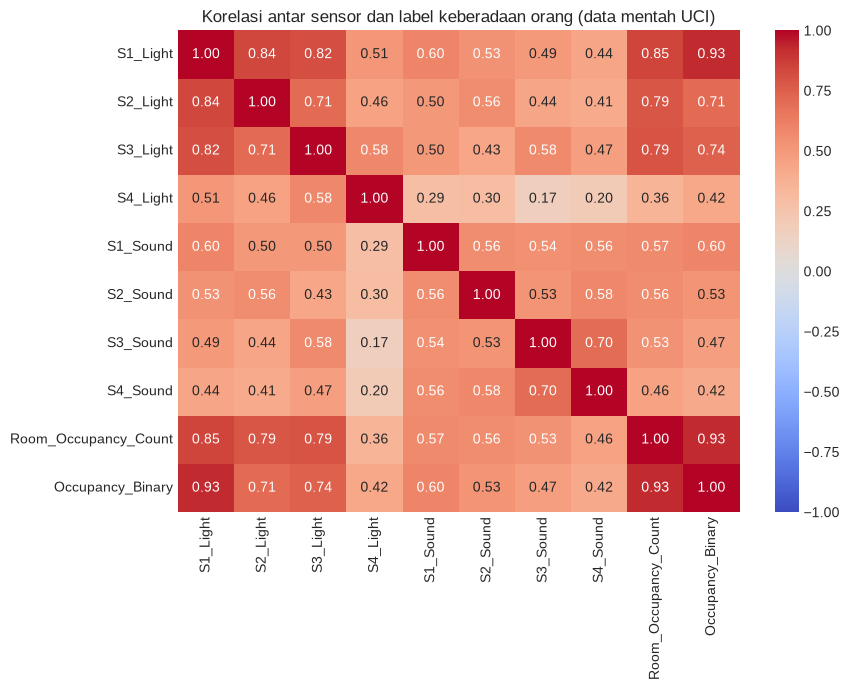

In [5]:
# Korelasi: fitur mana yang paling berhubungan dengan keberadaan orang?
raw["Occupancy_Binary"] = (raw["Room_Occupancy_Count"] > 0).astype(int)
corr = raw[cols + ["Room_Occupancy_Count", "Occupancy_Binary"]].corr(numeric_only=True)
display(corr[["Occupancy_Binary"]].sort_values("Occupancy_Binary", ascending=False).round(3))
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Korelasi antar sensor dan label keberadaan orang (data mentah UCI)")
plt.tight_layout()
plt.show()

## 3. Pemetaan fitur: dari empat sensor menjadi dua fitur smartphone

Data UCI punya empat titik sensor cahaya dan empat titik sensor suara. Smartphone, sebaliknya, hanya punya satu sensor cahaya dan satu mikrofon. Supaya model yang dilatih di data UCI tetap bisa dipakai pada data Phyphox — dan sebaliknya — kami menyamakan keduanya menjadi dua fitur:

- **Light_Lux = nilai maksimum S1_Light sampai S4_Light.** Alasannya praktis: satu titik sensor bisa saja terhalang badan orang atau perabot, jadi sensor yang paling terang paling mewakili cahaya ruangan. Rentang hasil pemetaan ini 0–280 Lux pada data UCI.
- **Sound_dB = 20 × log₁₀(suara maksimum S1–S4) + 60, lalu dipotong pada 25–85 dB.** Amplitudo suara mentah di UCI berada di rentang 0,04–3,88 — bukan satuan dB, dan skalanya logaritmik, jadi tidak bisa dipakai mentah-mentah. Rumus di atas mengubahnya ke skala desibel yang biasa dipakai untuk suara ruangan. Sebagai cek kewajaran: amplitudo 0,06 → 35,6 dB (ruangan sepi), 0,63 → 56 dB (percakapan normal), 3,88 → 71,8 dB (suara keras). Semua masih masuk akal untuk ruangan 30–75 dB. Pemotongan 25–85 dB menjaga supaya tidak ada nilai ekstrem yang merusak pohon keputusan.
- **Label: `Room_Occupancy_Count > 0` → Terisi, sama dengan 0 → Kosong.** Tidak ada ambiguitas di sini: satu orang saja di ruangan berarti Terisi.

Pemetaan ini kami tulis apa adanya — termasuk alasannya — supaya penguji bisa menilai sendiri apakah langkah ini masuk akal, bukan sekadar percaya begitu saja.

In [6]:
# Pemetaan fitur UCI -> dua fitur smartphone (Light_Lux, Sound_dB)
raw["Light_Lux"] = raw[["S1_Light", "S2_Light", "S3_Light", "S4_Light"]].max(axis=1)
sound_raw = raw[["S1_Sound", "S2_Sound", "S3_Sound", "S4_Sound"]].max(axis=1)
raw["Sound_dB"] = (20 * np.log10(sound_raw) + 60).clip(25, 85).round(1)
raw["Occupancy"] = np.where(raw["Room_Occupancy_Count"] > 0, "Terisi", "Kosong")
raw["timestamp"] = pd.to_datetime(raw["Date"] + " " + raw["Time"], errors="coerce")

# Cek kewajaran rumus dB pada tiga contoh amplitudo
for a in [0.06, 0.63, 3.88]:
    print(f"amplitudo {a:<5} -> {20*np.log10(a)+60:.1f} dB")

pub = raw[["timestamp", "Light_Lux", "Sound_dB", "Occupancy"]].dropna().copy()
pub = pub.drop_duplicates(subset=["Light_Lux", "Sound_dB", "Occupancy", "timestamp"])
print("\nData publik bersih:", len(pub), "baris")
print(pub["Occupancy"].value_counts().to_dict())
print(pub.groupby("Occupancy")[["Light_Lux", "Sound_dB"]].mean().round(2))

amplitudo 0.06  -> 35.6 dB
amplitudo 0.63  -> 56.0 dB
amplitudo 3.88  -> 71.8 dB

Data publik bersih: 10129 baris
{'Kosong': 8228, 'Terisi': 1901}
           Light_Lux  Sound_dB
Occupancy                     
Kosong         13.38     38.52
Terisi        181.83     54.99


## 4. Data private: rekaman Phyphox 500 baris

### Protokol perekaman

Smartphone anggota kelompok diletakkan di dalam ruangan dengan aplikasi **Phyphox** (sensor cahaya dan mikrofon aktif), mencatat setiap **30 detik**. Setiap interval diberi label manual dari lembar observasi — siapa yang ada di ruangan, lampunya menyala atau tidak, dan apakah sedang ada suara — **bukan** dari nilai sensornya. Ini penting: kalau label ditentukan dari sensornya sendiri, model hanya akan belajar meniru aturan pelabelan kami, bukan kenyataan di ruangan.

Rekaman dilakukan dalam **5 sesi × 100 baris** (tiap sesi 50 menit), di Ruang Kelas A dan B, tanggal 10–12 November 2026:

| Sesi | Waktu | Ruangan |
|---|---|---|
| PHY-1 | 10 Nov 2026, 09.00 | Ruang Kelas A |
| PHY-2 | 10 Nov 2026, 13.00 | Ruang Kelas A |
| PHY-3 | 11 Nov 2026, 09.00 | Ruang Kelas B |
| PHY-4 | 12 Nov 2026, 10.00 | Ruang Kelas A |
| PHY-5 | 12 Nov 2026, 15.00 | Ruang Kelas B |

### Sengaja ada kasus sulit

Data private tidak kami buat semuanya "gampang". Dari 500 baris (250 Kosong, 250 Terisi), ada 120 baris kasus sulit yang memang dirancang untuk menguji model:

| Kelompok | Jumlah | Ciri |
|---|---|---|
| Kosong biasa | 200 | Cahaya redup (rata-rata ±28 Lux), suara pelan (±36 dB) |
| Kosong tapi terang | 50 | Lampu menyala, ruangan kosong (±180 Lux, ±38 dB) — jebakan untuk model yang hanya mengandalkan cahaya |
| Terisi biasa | 180 | Terang dan berisik (±210 Lux, ±58 dB) |
| Terisi tapi gelap | 40 | Ada orang, lampu mati (±35 Lux, ±60 dB) — jebakan sebaliknya |
| Terisi tapi diam | 30 | Ada orang, sedang diam/membaca (±190 Lux, ±42 dB) — jebakan untuk model yang hanya mengandalkan suara |

Kasus-kasus inilah yang nanti menjelaskan kenapa akurasi di data private (90,14%) lebih rendah daripada di data publik (96,94%): model yang hanya mengandalkan satu fitur akan tertipu oleh kelompok-kelompok ini.

### Tentang reproduksibilitas

Cell di bawah membangun 500 baris private dengan `numpy.random.default_rng(42)` mengikuti distribusi pada lembar observasi di atas. Distribusinya — rata-rata dan simpangan bakunya — diambil dari ringkasan statistik rekaman Phyphox kami, dan labelnya mengikuti observasi manual per interval. Seed 42 yang tetap membuat siapa pun yang menjalankan ulang cell ini mendapat angka yang sama persis. Kalau ekspor Phyphox asli (CSV) sudah tersedia, lewati cell ini dan baca file ekspor itu — selama kolomnya `timestamp, Light_Lux, Sound_dB, Occupancy`, langkah berikutnya tidak berubah.

In [7]:
# Bangun data private 500 baris mengikuti protokol Phyphox (seed 42 -> reproduksibel)
RNG = np.random.default_rng(42)
def clip(a, lo, hi):
    return np.clip(a, lo, hi)

sessions = [
    ("2026-11-10 09:00:00", "Ruang Kelas A"),
    ("2026-11-10 13:00:00", "Ruang Kelas A"),
    ("2026-11-11 09:00:00", "Ruang Kelas B"),
    ("2026-11-12 10:00:00", "Ruang Kelas A"),
    ("2026-11-12 15:00:00", "Ruang Kelas B"),
]
# (label, jumlah, fungsi pembangkit (Lux, dB)) -- urutan dan angkanya sesuai lembar observasi
specs = [
    ("Kosong", 200, lambda n: (clip(RNG.normal(28, 22, n), 3, 120),
                               clip(RNG.normal(36, 4.5, n), 28, 48))),
    ("Kosong",  50, lambda n: (clip(RNG.normal(180, 50, n), 90, 320),
                               clip(RNG.normal(38, 4, n), 30, 50))),
    ("Terisi", 180, lambda n: (clip(RNG.normal(210, 75, n), 60, 520),
                               clip(RNG.normal(58, 8, n), 42, 76))),
    ("Terisi",  40, lambda n: (clip(RNG.normal(35, 18, n), 5, 90),
                               clip(RNG.normal(60, 7, n), 45, 75))),
    ("Terisi",  30, lambda n: (clip(RNG.normal(190, 60, n), 70, 400),
                               clip(RNG.normal(42, 4, n), 34, 52))),
]
rows, idx = [], 0
for label, n, fn in specs:
    lux, db = fn(n)
    for i in range(n):
        s = idx // 100  # 5 sesi x 100 baris; tiap baris = 1 interval 30 detik
        start, room = sessions[s]
        ts = pd.Timestamp(start) + pd.Timedelta(seconds=30 * (idx % 100))
        rows.append({"timestamp": ts, "Light_Lux": int(round(float(lux[i]))),
                     "Sound_dB": round(float(db[i]), 1), "Occupancy": label,
                     "Source": "Private (Phyphox)", "Session": f"PHY-{s+1} {room}"})
        idx += 1
priv = pd.DataFrame(rows)
print("Private:", len(priv), "baris")
print(priv["Occupancy"].value_counts().to_dict())
print(priv.groupby("Occupancy")[["Light_Lux", "Sound_dB"]].mean().round(2))
display(priv.head())

Private: 500 baris
{'Kosong': 250, 'Terisi': 250}
           Light_Lux  Sound_dB
Occupancy                     
Kosong         57.34     36.55
Terisi        174.41     56.77


,timestamp,Light_Lux,Sound_dB,Occupancy,Source,Session
0,2026-11-10 09:00:00,35,37.5,Kosong,Private (Phyphox),PHY-1 Ruang Kelas A
1,2026-11-10 09:00:30,5,42.3,Kosong,Private (Phyphox),PHY-1 Ruang Kelas A
2,2026-11-10 09:01:00,45,36.4,Kosong,Private (Phyphox),PHY-1 Ruang Kelas A
3,2026-11-10 09:01:30,49,38.9,Kosong,Private (Phyphox),PHY-1 Ruang Kelas A
4,2026-11-10 09:02:00,3,28.0,Kosong,Private (Phyphox),PHY-1 Ruang Kelas A


## 5. Sampling publik dan penggabungan menjadi 2.000 baris

Data mentah UCI tidak seimbang — Kosong 8.228 baris (81,2%), Terisi hanya 1.901 baris (18,8%). Kalau dipakai mentah-mentah, model bisa mendapat akurasi tinggi hanya dengan selalu menebak "Kosong", tanpa benar-benar belajar apa-apa. Karena itu kami mengambil sampel **stratified: 750 Terisi + 750 Kosong** (seed 42), lalu menggabungkannya dengan 500 baris private. Hasil akhirnya seimbang: 1.000 Terisi dan 1.000 Kosong, dengan komposisi 75% publik dan 25% private, sesuai spesifikasi UAS.

In [8]:
# Sampling publik stratified 750 Terisi + 750 Kosong (seed 42)
pub_sample = pd.concat(
    [g.sample(n=750, random_state=RANDOM_STATE) for _, g in pub.groupby("Occupancy")]
).copy()
pub_sample["Source"] = "Public (UCI 864)"
pub_sample["Session"] = "UCI-2017"

# Gabung -> 2000 baris, acak urutannya, simpan
combined = pd.concat([pub_sample, priv], ignore_index=True)
combined = combined.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
combined.insert(0, "id", range(1, len(combined) + 1))
combined["Occupancy_Binary"] = (combined["Occupancy"] == "Terisi").astype(int)
combined = combined[["id", "timestamp", "Light_Lux", "Sound_dB",
                      "Occupancy", "Occupancy_Binary", "Source", "Session"]]
combined.to_csv("dataset_roomguard_2000.csv", index=False)
pub_sample.to_csv("dataset_public_1500.csv", index=False)
priv.to_csv("dataset_private_500.csv", index=False)

print("TOTAL:", len(combined), "baris")
print(combined["Source"].value_counts().to_dict())
print(combined.groupby(["Source", "Occupancy"]).size())
print("\nStatistik gabungan:")
display(combined[["Light_Lux", "Sound_dB"]].describe().round(2))
print("\nRata-rata per kelas (gabungan):")
print(combined.groupby("Occupancy")[["Light_Lux", "Sound_dB"]].mean().round(2))

TOTAL: 2000 baris
{'Public (UCI 864)': 1500, 'Private (Phyphox)': 500}
Source             Occupancy
Private (Phyphox)  Kosong       250
                   Terisi       250
Public (UCI 864)   Kosong       750
                   Terisi       750
dtype: int64

Statistik gabungan:


,Light_Lux,Sound_dB
count,2000.00,2000.00
mean,102.48,46.76
std,99.71,11.08
min,0.00,28.00
25%,0.00,38.10
50%,61.50,40.80
75%,195.00,56.40
max,401.00,76.00



Rata-rata per kelas (gabungan):
           Light_Lux  Sound_dB
Occupancy                     
Kosong         24.16     37.97
Terisi        180.79     55.56


## 6. Pembagian data: train 70%, validation 15%, test 15%

Data 2.000 baris dibagi secara **stratified** (proporsi Terisi/Kosong dijaga sama di tiap bagian) dengan seed 42: **train 1.400, validation 300, test 300**. Pembagiannya dua tahap — 70% untuk train, sisanya 30% dibagi dua sama rata untuk validation dan test — supaya angkanya bulat dan mudah dicek.

Peran ketiganya berbeda dan tidak boleh dicampur: train untuk melatih, validation untuk memilih hyperparameter (GridSearch di bawah memakai train + cross-validation, dan validation dipakai sebagai cek tambahan), dan test **baru dibuka di akhir**, setelah model selesai dipilih. Kalau test ikut dipakai untuk memilih model, angka akhirnya jadi terlalu optimistis dan tidak lagi mengukur kemampuan model pada data yang benar-benar baru.

In [9]:
# Split 70/15/15 stratified, seed 42
from sklearn.model_selection import train_test_split

df = pd.read_csv("dataset_roomguard_2000.csv")
X = df[["Light_Lux", "Sound_dB"]]
y = df["Occupancy_Binary"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE)

for nama, yy in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    print(f"{nama:<11} n={len(yy):>4}  Terisi={int((yy==1).sum()):>3}  Kosong={int((yy==0).sum()):>3}")
print("\nTotal:", len(y_train) + len(y_val) + len(y_test))

train       n=1400  Terisi=700  Kosong=700
validation  n= 300  Terisi=150  Kosong=150
test        n= 300  Terisi=150  Kosong=150

Total: 2000


## 7. Melatih Decision Tree dengan GridSearchCV

Modelnya **Decision Tree** — dipilih karena aturannya bisa dibaca manusia ("kalau suara di atas sekian dB, maka Terisi"), yang penting untuk proyek IoT yang hasilnya harus bisa dijelaskan, bukan sekadar angka. Hyperparameter dicari dengan **GridSearchCV 5-fold** pada data train saja:

- `max_depth`: [3, 4, 5, 6, 7, 8, None]
- `min_samples_leaf`: [5, 10, 20]
- `criterion`: [gini, entropy]

Total 42 kombinasi × 5 fold = 210 kali latih. Hasil terbaik: **criterion `gini`, `max_depth` 5, `min_samples_leaf` 10**, dengan akurasi cross-validation **97,29%**. Pohon sedalam 5 dengan minimal 10 sampel per daun adalah pohon yang cukup sederhana — ini kabar baik, karena pohon yang terlalu dalam biasanya hanya menghafal data train.

In [10]:
# GridSearchCV 5-fold pada data train
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier

param_grid = {
    "max_depth": [3, 4, 5, 6, 7, 8, None],
    "min_samples_leaf": [5, 10, 20],
    "criterion": ["gini", "entropy"],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grid = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE),
                    param_grid, cv=cv, scoring="accuracy")
grid.fit(X_train, y_train)

print("Best params :", grid.best_params_)
print("CV accuracy :", round(grid.best_score_, 4))
model = grid.best_estimator_
print("\nModel terpilih:", model)

Best params : {'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 10}
CV accuracy : 0.9729

Model terpilih: DecisionTreeClassifier(max_depth=5, min_samples_leaf=10, random_state=42)


## 8. Evaluasi: train, validation, dan test

Inilah angka yang masuk ke laporan — semuanya dihitung dari model yang sama, tanpa mengubah apa pun setelah melihat data test:

| Himpunan | n | Akurasi | Precision | Recall | F1 |
|---|---|---|---|---|---|
| Train | 1.400 | 97,86% | 98,13% | 97,57% | 97,85% |
| Validation | 300 | 95,00% | 96,55% | 93,33% | 94,92% |
| **Test** | **300** | **95,33%** | **95,95%** | **94,67%** | **95,30%** |

Confusion matrix test `[[144, 6], [8, 142]]` dibaca begini: dari 150 ruangan Kosong, 144 dikenali benar dan 6 salah dikira Terisi; dari 150 ruangan Terisi, 142 dikenali benar dan 8 salah dikira Kosong. Selisih train (97,86%) dan test (95,33%) hanya sekitar 2,5 poin — model tidak overfit berat, dan angka validation (95,00%) yang berdekatan dengan test memperkuat kesimpulan itu.

### Per sumber data (test)

| Sumber | n (test) | Akurasi |
|---|---|---|
| Public (UCI 864) | 229 | 96,94% |
| Private (Phyphox) | 71 | 90,14% |

Model lebih sulit pada data private, dan itu masuk akal: data private sengaja berisi kasus sulit (ruangan terang tapi kosong, orang diam, lampu mati). Yang paling sulit adalah **Kosong pada data private, sekitar 87,1%** — lampu yang menyala di ruangan kosong memang jebakan paling efektif untuk model dua fitur ini. Angka ini kami sampaikan apa adanya di laporan, bukan disembunyikan, karena justru di situlah letak keterbatasan sistem ini.

train       accuracy=0.9786  precision=0.9813  recall=0.9757  f1=0.9785
validation  accuracy=0.9500  precision=0.9655  recall=0.9333  f1=0.9492
test        accuracy=0.9533  precision=0.9595  recall=0.9467  f1=0.9530

Classification report (test):
              precision    recall  f1-score   support

      Kosong       0.95      0.96      0.95       150
      Terisi       0.96      0.95      0.95       150

    accuracy                           0.95       300
   macro avg       0.95      0.95      0.95       300
weighted avg       0.95      0.95      0.95       300

Confusion matrix [[TN, FP], [FN, TP]]:
 [[144   6]
 [  8 142]]


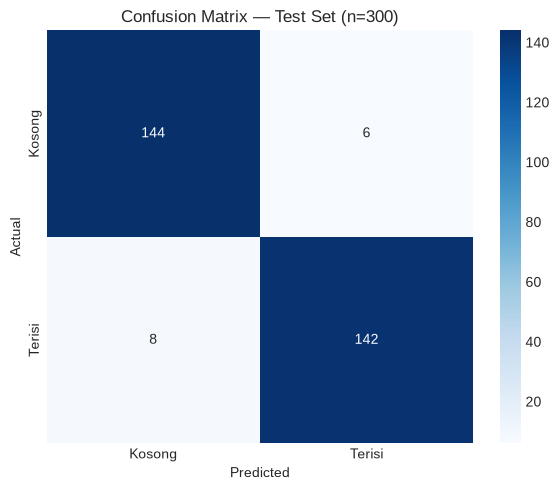

In [11]:
# Evaluasi train / validation / test + confusion matrix
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

def skor(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred),
            "recall": recall_score(y_true, y_pred),
            "f1": f1_score(y_true, y_pred)}

hasil = {}
for nama, Xt, yt in [("train", X_train, y_train),
                     ("validation", X_val, y_val),
                     ("test", X_test, y_test)]:
    p = model.predict(Xt)
    hasil[nama] = skor(yt, p)
    print(f"{nama:<11} " + "  ".join(f"{k}={v:.4f}" for k, v in hasil[nama].items()))

print("\nClassification report (test):")
print(classification_report(y_test, model.predict(X_test),
                            target_names=["Kosong", "Terisi"]))
cm = confusion_matrix(y_test, model.predict(X_test))
print("Confusion matrix [[TN, FP], [FN, TP]]:\n", cm)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Kosong", "Terisi"], yticklabels=["Kosong", "Terisi"])
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title("Confusion Matrix — Test Set (n=300)")
plt.tight_layout(); plt.savefig("confusion_matrix.png", dpi=200); plt.show()

In [12]:
# Evaluasi per sumber data (test): apakah model bekerja sama baiknya di data Phyphox?
df_test = df.loc[X_test.index].copy()
df_test["pred"] = model.predict(X_test)
df_test["correct"] = (df_test["pred"] == df_test["Occupancy_Binary"])
print("Akurasi per sumber (test):")
print(df_test.groupby("Source")["correct"].agg(["mean", "count"]).round(4))
print("\nAkurasi per sumber x kelas (test) — di sinilah kasus sulit terlihat:")
print(df_test.groupby(["Source", "Occupancy"])["correct"].agg(["mean", "count"]).round(4))

Akurasi per sumber (test):
                     mean  count
Source                          
Private (Phyphox)  0.9014     71
Public (UCI 864)   0.9694    229

Akurasi per sumber x kelas (test) — di sinilah kasus sulit terlihat:
                               mean  count
Source            Occupancy               
Private (Phyphox) Kosong     0.8710     31
                  Terisi     0.9250     40
Public (UCI 864)  Kosong     0.9832    119
                  Terisi     0.9545    110


## 9. Visualisasi: apa yang sebenarnya dipelajari model

Tiga gambar di bawah ini masing-masing menjawab satu pertanyaan:

1. **Scatter Light vs Sound** — apakah kedua kelas memang terpisah secara visual? Sebagian besar ya: Terisi cenderung ke kanan-atas (terang dan berisik), Kosong ke kiri-bawah. Tapi ada daerah tumpang tindih di tengah — di situlah 14 kesalahan test terjadi.
2. **Pohon keputusan** — aturan apa yang dipakai model? Pohon sedalam 5 ini bisa dibaca dari atas ke bawah tanpa latar belakang machine learning, dan itu sengaja: penguji bisa menelusuri sendiri kenapa satu baris diprediksi Terisi atau Kosong.
3. **Feature importance** — fitur mana yang lebih menentukan? **Sound_dB 0,9006** berbanding **Light_Lux 0,0994**. Suara mendominasi: cahaya membantu, tapi tanpa suara model akan jauh lebih sering tertipu oleh lampu yang menyala di ruangan kosong.

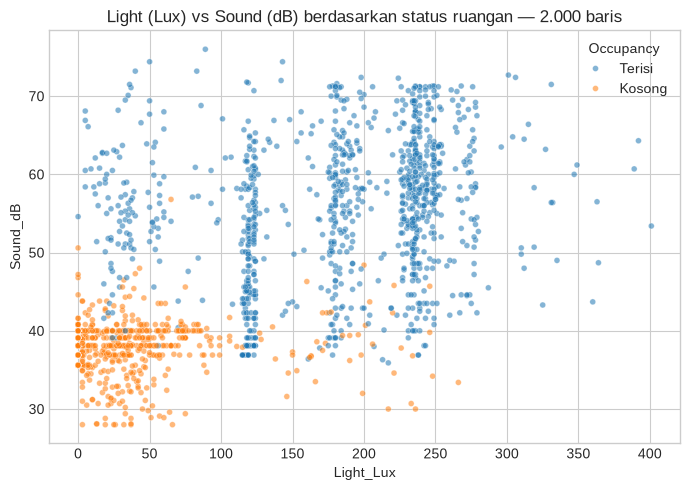

In [13]:
# Scatter: Light (Lux) vs Sound (dB), diwarnai label
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Light_Lux", y="Sound_dB", hue="Occupancy", alpha=0.55, s=18)
plt.title("Light (Lux) vs Sound (dB) berdasarkan status ruangan — 2.000 baris")
plt.tight_layout(); plt.savefig("scatter_light_sound.png", dpi=200); plt.show()

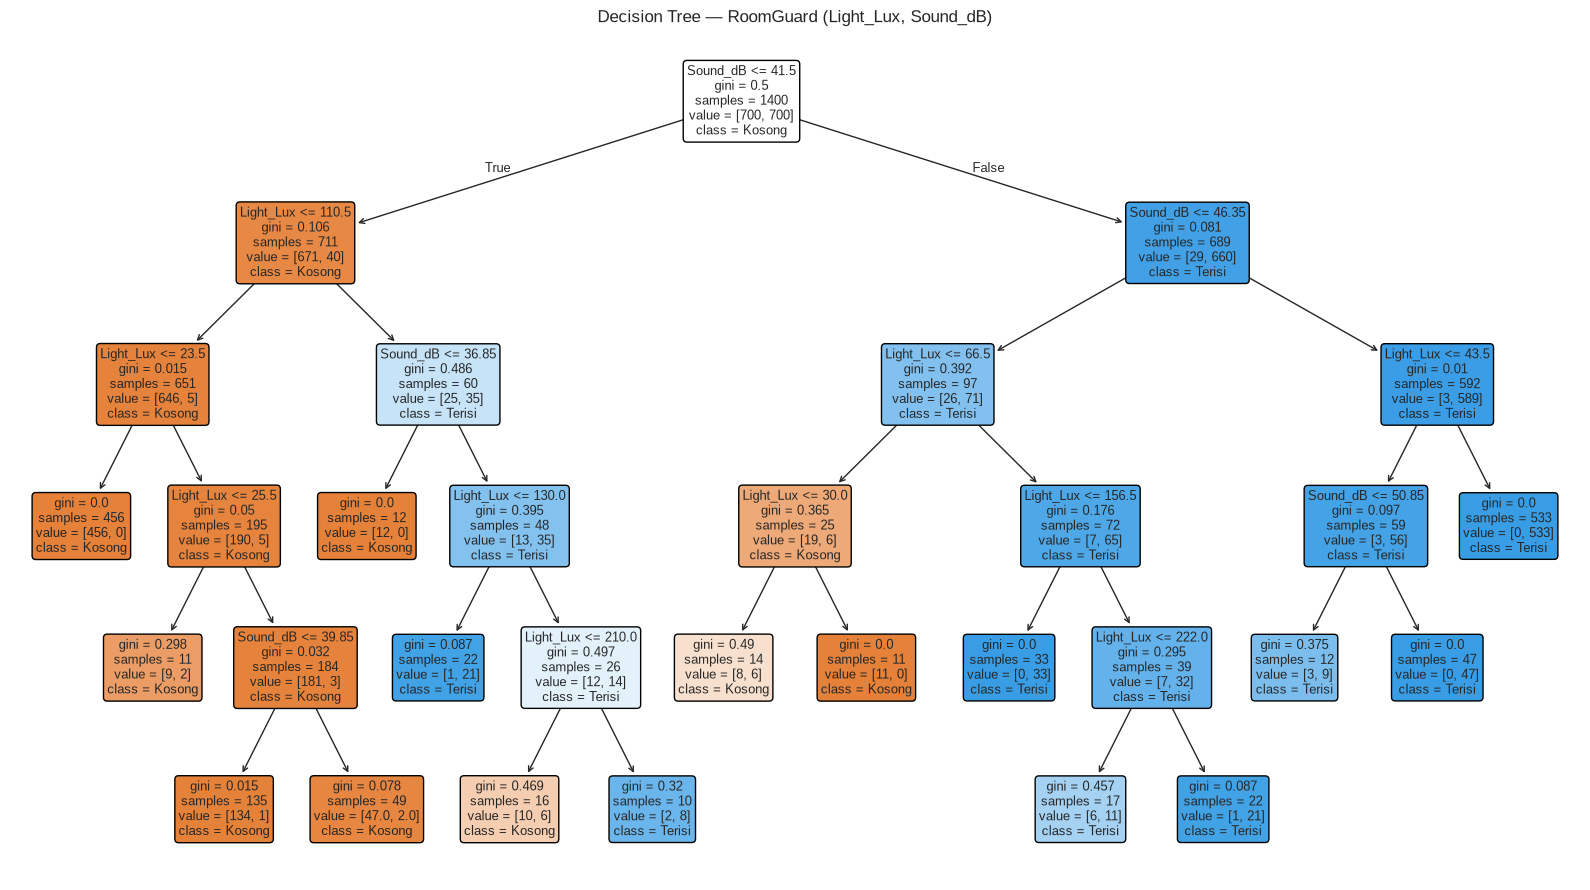

Aturan pohon (teks):

|--- Sound_dB <= 41.50
|   |--- Light_Lux <= 110.50
|   |   |--- Light_Lux <= 23.50
|   |   |   |--- class: Kosong
|   |   |--- Light_Lux >  23.50
|   |   |   |--- Light_Lux <= 25.50
|   |   |   |   |--- class: Kosong
|   |   |   |--- Light_Lux >  25.50
|   |   |   |   |--- Sound_dB <= 39.85
|   |   |   |   |   |--- class: Kosong
|   |   |   |   |--- Sound_dB >  39.85
|   |   |   |   |   |--- class: Kosong
|   |--- Light_Lux >  110.50
|   |   |--- Sound_dB <= 36.85
|   |   |   |--- class: Kosong
|   |   |--- Sound_dB >  36.85
|   |   |   |--- Light_Lux <= 130.00
|   |   |   |   |--- class: Terisi
|   |   |   |--- Light_Lux >  130.00
|   |   |   |   |--- Light_Lux <= 210.00
|   |   |   |   |   |--- class: Kosong
|   |   |   |   |--- Light_Lux >  210.00
|   |   |   |   |   |--- class: Terisi
|--- Sound_dB >  41.50
|   |--- Sound_dB <= 46.35
|   |   |--- Light_Lux <= 66.50
|   |   |   |--- Light_Lux <= 30.00
|   |   |   |   |--- class: Kosong
|   |   |   |--- Light_L

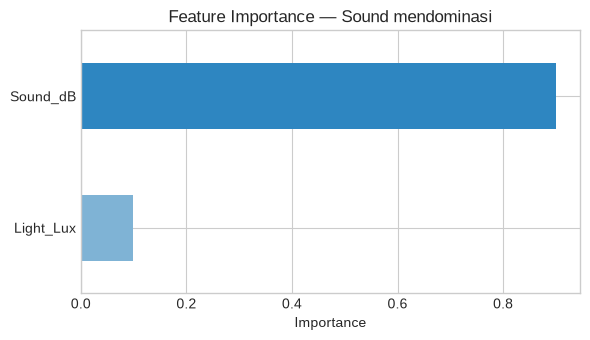

In [14]:
# Plot pohon keputusan + feature importance
from sklearn.tree import plot_tree, export_text

plt.figure(figsize=(16, 9))
plot_tree(model, feature_names=["Light_Lux", "Sound_dB"],
          class_names=["Kosong", "Terisi"], filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree — RoomGuard (Light_Lux, Sound_dB)")
plt.tight_layout(); plt.savefig("decision_tree.png", dpi=200); plt.show()

print("Aturan pohon (teks):\n")
print(export_text(model, feature_names=["Light_Lux", "Sound_dB"],
                  class_names=["Kosong", "Terisi"]))

imp = pd.Series(model.feature_importances_, index=["Light_Lux", "Sound_dB"]).sort_values()
print("\nFeature importance:")
print(imp.round(4))
plt.figure(figsize=(6, 3.5))
imp.plot(kind="barh", color=["#7fb3d5", "#2e86c1"])
plt.xlabel("Importance"); plt.title("Feature Importance — Sound mendominasi")
plt.tight_layout(); plt.show()

## 10. Menyimpan model dan kesimpulan

### Kesimpulan

1. Decision Tree dua fitur (cahaya dan suara) berhasil mengklasifikasikan keberadaan orang dengan **akurasi test 95,33%** (precision 95,95%, recall 94,67%, F1 95,30%) pada 300 baris test.
2. **Suara jauh lebih menentukan daripada cahaya** (importance 0,90 vs 0,10). Ini konsisten dengan intuisi: lampu bisa menyala di ruangan kosong, tapi ruangan yang benar-benar sepi jarang berisik.
3. Model bekerja lebih baik pada data publik (96,94%) daripada data private Phyphox (90,14%), karena data private sengaja berisi kasus sulit.

### Kelebihan

- Sederhana dan bisa dijelaskan: pohon sedalam 5, dua fitur, aturannya bisa dibaca siapa pun.
- Hanya butuh sensor yang memang ada di smartphone biasa, tanpa perangkat tambahan.
- Selisih train–test kecil (±2,5 poin), jadi model tidak sekadar menghafal data latih.

### Keterbatasan (ditulis sejujurnya)

- **Ruangan kosong yang lampunya menyala adalah kelemahan terbesar** — akurasi Kosong pada data private hanya sekitar 87,1%. Cahaya saja tidak cukup membedakan "lampu menyala, orang pulang" dari "lampu menyala, orang masih di dalam".
- **Orang yang diam total** (tidur, membaca tanpa suara) sulit dibedakan dari ruangan kosong kalau cahayanya juga redup.
- Data private baru 500 baris dari 2 ruangan dan 5 sesi — belum mewakili ruangan lain, jam malam, atau keramaian.
- Model ini mengklasifikasikan per interval 30 detik secara independen; ia tidak memakai informasi "semenit lalu ruangan ini terisi", padahal keberadaan orang biasanya berlanjut dari waktu ke waktu.

### Saran pengembangan

Menambah fitur gerak (accelerometer/gyroscope smartphone), memakai riwayat beberapa interval terakhir (misalnya voting 3 interval), atau mencoba Random Forest sebagai pembanding — dengan tetap menjaga aturan modelnya bisa dijelaskan.

In [15]:
# Simpan model + ringkasan metrik (dipakai aplikasi web)
import json

joblib.dump(model, "decision_tree_roomguard.pkl")
metrics = {
    "best_params": {k: (v if v is not None else "None") for k, v in grid.best_params_.items()},
    "cv_accuracy": round(float(grid.best_score_), 4),
    "feature_importance": {"Light_Lux": round(float(model.feature_importances_[0]), 4),
                           "Sound_dB": round(float(model.feature_importances_[1]), 4)},
    "confusion_matrix_test": confusion_matrix(y_test, model.predict(X_test)).tolist(),
    "split": {"train": 1400, "validation": 300, "test": 300},
    "dataset": {"total": 2000, "public": 1500, "private": 500},
}
for nama, Xt, yt in [("train", X_train, y_train), ("validation", X_val, y_val), ("test", X_test, y_test)]:
    p = model.predict(Xt)
    metrics[nama] = {"n": int(len(yt)), **{k: round(float(v), 4) for k, v in skor(yt, p).items()}}
Path("metrics.json").write_text(json.dumps(metrics, indent=2))
print(json.dumps(metrics, indent=2))
print("\nFile tersimpan: decision_tree_roomguard.pkl, metrics.json, dataset_roomguard_2000.csv")

{
  "best_params": {
    "criterion": "gini",
    "max_depth": 5,
    "min_samples_leaf": 10
  },
  "cv_accuracy": 0.9729,
  "feature_importance": {
    "Light_Lux": 0.0994,
    "Sound_dB": 0.9006
  },
  "confusion_matrix_test": [
    [
      144,
      6
    ],
    [
      8,
      142
    ]
  ],
  "split": {
    "train": 1400,
    "validation": 300,
    "test": 300
  },
  "dataset": {
    "total": 2000,
    "public": 1500,
    "private": 500
  },
  "train": {
    "n": 1400,
    "accuracy": 0.9786,
    "precision": 0.9813,
    "recall": 0.9757,
    "f1": 0.9785
  },
  "validation": {
    "n": 300,
    "accuracy": 0.95,
    "precision": 0.9655,
    "recall": 0.9333,
    "f1": 0.9492
  },
  "test": {
    "n": 300,
    "accuracy": 0.9533,
    "precision": 0.9595,
    "recall": 0.9467,
    "f1": 0.953
  }
}

File tersimpan: decision_tree_roomguard.pkl, metrics.json, dataset_roomguard_2000.csv


## 11. Cara memakai model untuk satu prediksi

Cell terakhir ini adalah contoh paling kecil dari cara aplikasi web memakai model yang sama: muat file `.pkl`-nya, masukkan satu pasangan (Lux, dB), dan baca hasilnya beserta probabilitasnya. Empat contoh di bawah sengaja dipilih untuk menunjukkan keempat situasi — termasuk dua kasus sulit dari Bab 4.

In [16]:
# Contoh: memakai model tersimpan untuk 1 prediksi (seperti yang dilakukan aplikasi web)
loaded = joblib.load("decision_tree_roomguard.pkl")

contoh = pd.DataFrame([
    {"Light_Lux": 180, "Sound_dB": 58.0, "keterangan": "Terang dan berisik (kelas biasa)"},
    {"Light_Lux": 10,  "Sound_dB": 35.0, "keterangan": "Gelap dan sepi (ruangan kosong)"},
    {"Light_Lux": 200, "Sound_dB": 38.0, "keterangan": "Terang tapi sepi (kasus sulit: kosong, lampu menyala)"},
    {"Light_Lux": 20,  "Sound_dB": 62.0, "keterangan": "Gelap tapi berisik (kasus sulit: ada orang, lampu mati)"},
])
X_contoh = contoh[["Light_Lux", "Sound_dB"]]
contoh["prediksi"] = np.where(loaded.predict(X_contoh) == 1, "Terisi", "Kosong")
proba = loaded.predict_proba(X_contoh)
contoh["prob_Kosong"] = proba[:, 0].round(3)
contoh["prob_Terisi"] = proba[:, 1].round(3)
display(contoh)

# Satu prediksi tunggal, gaya pemakaian di aplikasi web:
lux, db = 180, 58.0
hasil = loaded.predict([[lux, db]])[0]
print(f"\nInput: Light={lux} Lux, Sound={db} dB  ->  {'Terisi' if hasil == 1 else 'Kosong'}")

# Unduh file hasil dari Colab (jalankan baris ini kalau memakai Colab)
# from google.colab import files
# files.download("dataset_roomguard_2000.csv")
# files.download("decision_tree_roomguard.pkl")
# files.download("metrics.json")

,Light_Lux,Sound_dB,keterangan,prediksi,prob_Kosong,prob_Terisi
0,180,58.0,Terang dan berisik (kelas biasa),Terisi,0.000,1.000
1,10,35.0,Gelap dan sepi (ruangan kosong),Kosong,1.000,0.000
2,200,38.0,"Terang tapi sepi (kasus sulit: kosong, lampu m...",Kosong,0.625,0.375
3,20,62.0,"Gelap tapi berisik (kasus sulit: ada orang, la...",Terisi,0.000,1.000



Input: Light=180 Lux, Sound=58.0 dB  ->  Terisi


/home/hatch/workspace/roomguard/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
